# Phase 1 hypotheses and energy measurements

We compared quantized AkidaNet in Keras with the converted model running on the AKD1000. We used 2,000 ImageNet-C images per condition, two per class, at five severities each for fog, Gaussian noise and contrast. A disagreement is when the two models give different top-1 labels for the same image.

We used severity 1 of each corruption as the reference wherever we needed one. Our run used corrupted images only. BrainChip reports 61.30% top-1 accuracy on clean ImageNet for this model.

The predictions and energy measurements are in `results_card/predictions.csv` and `results_card/energy.csv`. We grouped the labels using `imagenet_superclasses.csv` and used `results_card/keras_top2_h1.csv` for the score comparison in H1.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path

FIG = Path('../figures/phase1_human'); FIG.mkdir(parents=True, exist_ok=True)
BLUE, ORANGE, AQUA = '#2a78d6', '#eb6834', '#1baf7a'
INK, MUTED, GRID = '#0b0b0b', '#52514e', '#e4e3df'
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'axes.edgecolor': MUTED,
                     'axes.labelcolor': INK, 'xtick.color': MUTED, 'ytick.color': MUTED,
                     'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.6,
                     'lines.linewidth': 2, 'font.size': 10})

CORR = ['fog', 'gaussian_noise', 'contrast']
ANIMALS = ['dog', 'other mammal', 'bird', 'reptile/amphibian', 'fish', 'invertebrate']
rng = np.random.default_rng(0)
B = 5000  # bootstrap resamples

sc = pd.read_csv('imagenet_superclasses.csv').set_index('label')['superclass']
p = pd.read_csv('results_card/predictions.csv')
p['sc'] = p['label'].map(sc)
p['dis'] = p['keras_pred'] != p['akida_pred']
p.groupby('sc').size().div(15).astype(int).rename('images per condition').sort_values(ascending=False)

sc
device/instrument    408
dog                  236
other mammal         200
vehicle              144
invertebrate         122
bird                 118
clothing             114
food/plant           114
structure            114
container            112
other artifact       108
reptile/amphibian     88
furniture             44
fish                  32
nature/scene          32
other                 14
Name: images per condition, dtype: int64

## H1 · Do the models disagree more on dogs than on devices?

We expected the models to disagree more often on dog images than on images of devices or instruments. In each condition, we bootstrapped the difference in disagreement rates by resampling images within each group (236 dogs and 408 devices or instruments).

We counted a condition toward H1 if the entire 95% confidence interval for the difference (dogs minus devices) was above zero. We needed at least 8 of the 15 conditions to meet that rule.

In [2]:
def boot_rate(x):
    x = np.asarray(x, float)
    return x[rng.integers(0, len(x), (B, len(x)))].mean(1)

rows = []
for (c, s), g in p.groupby(['corruption', 'severity']):
    d, v = g.loc[g.sc == 'dog', 'dis'], g.loc[g.sc == 'device/instrument', 'dis']
    bd, bv = boot_rate(d), boot_rate(v)
    diff = bd - bv
    rows.append(dict(corruption=c, severity=s,
                     dog=d.mean(), dog_lo=np.quantile(bd, .025), dog_hi=np.quantile(bd, .975),
                     dev=v.mean(), dev_lo=np.quantile(bv, .025), dev_hi=np.quantile(bv, .975),
                     diff=d.mean() - v.mean(), diff_lo=np.quantile(diff, .025), diff_hi=np.quantile(diff, .975)))
h1 = pd.DataFrame(rows)
h1['dogs_higher'] = h1.diff_lo > 0
h1.round(3)

,corruption,severity,dog,dog_lo,dog_hi,dev,dev_lo,dev_hi,diff,diff_lo,diff_hi,dogs_higher
0,contrast,1,0.229,0.178,0.284,0.208,0.169,0.250,0.020,-0.044,0.088,False
1,contrast,2,0.271,0.216,0.331,0.228,0.186,0.270,0.043,-0.027,0.116,False
2,contrast,3,0.297,0.242,0.356,0.299,0.255,0.343,-0.002,-0.073,0.071,False
3,contrast,4,0.441,0.377,0.504,0.306,0.262,0.350,0.134,0.059,0.214,True
4,contrast,5,0.369,0.309,0.432,0.373,0.326,0.419,-0.004,-0.081,0.074,False
5,fog,1,0.216,0.165,0.271,0.225,0.186,0.267,-0.009,-0.074,0.057,False
6,fog,2,0.246,0.191,0.301,0.262,0.218,0.306,-0.016,-0.087,0.054,False
7,fog,3,0.284,0.229,0.343,0.270,0.225,0.314,0.014,-0.057,0.087,False
8,fog,4,0.305,0.246,0.364,0.294,0.250,0.341,0.011,-0.062,0.085,False
9,fog,5,0.280,0.225,0.335,0.277,0.235,0.321,0.003,-0.067,0.072,False


Dogs significantly higher in 3 of 15 conditions: [('contrast', 4), ('gaussian_noise', 4), ('gaussian_noise', 5)]
Verdict H1: REJECTED (rule: dogs higher in most, i.e. >= 8, of 15)


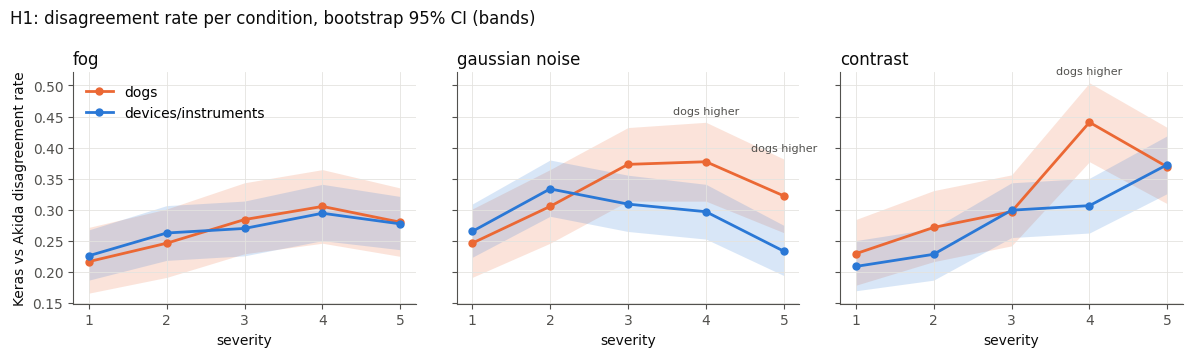

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6), sharey=True)
for ax, c in zip(axes, CORR):
    t = h1[h1.corruption == c]
    for k, col, name in [('dog', ORANGE, 'dogs'), ('dev', BLUE, 'devices/instruments')]:
        ax.fill_between(t.severity, t[k + '_lo'], t[k + '_hi'], color=col, alpha=.18, lw=0)
        ax.plot(t.severity, t[k], color=col, marker='o', ms=5, label=name)
    for _, r in t[t.dogs_higher].iterrows():  # mark conditions where the CI of the difference is above 0
        ax.annotate('dogs higher', (r.severity, r.dog_hi), textcoords='offset points', xytext=(0, 6),
                    ha='center', fontsize=8, color=MUTED)
    ax.set_title(c.replace('_', ' '), color=INK, loc='left')
    ax.set_xticks(range(1, 6)); ax.set_xlabel('severity')
axes[0].set_ylabel('Keras vs Akida disagreement rate')
axes[0].legend(frameon=False, loc='upper left')
fig.suptitle('H1: disagreement rate per condition, bootstrap 95% CI (bands)', x=0.01, ha='left', color=INK)
fig.tight_layout(); fig.savefig(FIG / 'h1_dog_vs_device_disagreement.png', dpi=150)

n = int(h1.dogs_higher.sum())
print(f'Dogs significantly higher in {n} of 15 conditions:',
      h1.loc[h1.dogs_higher, ['corruption', 'severity']].apply(tuple, axis=1).tolist())
print('Verdict H1:', 'NOT rejected' if n >= 8 else 'REJECTED', '(rule: dogs higher in most, i.e. >= 8, of 15)')

### Which labels get swapped within each group?

The matrices pool all 15 conditions. For each group, we kept images where the two models disagreed and both predictions stayed in the image's true group. Rows show the Keras prediction and columns show the Akida prediction. The axes follow ImageNet label order.

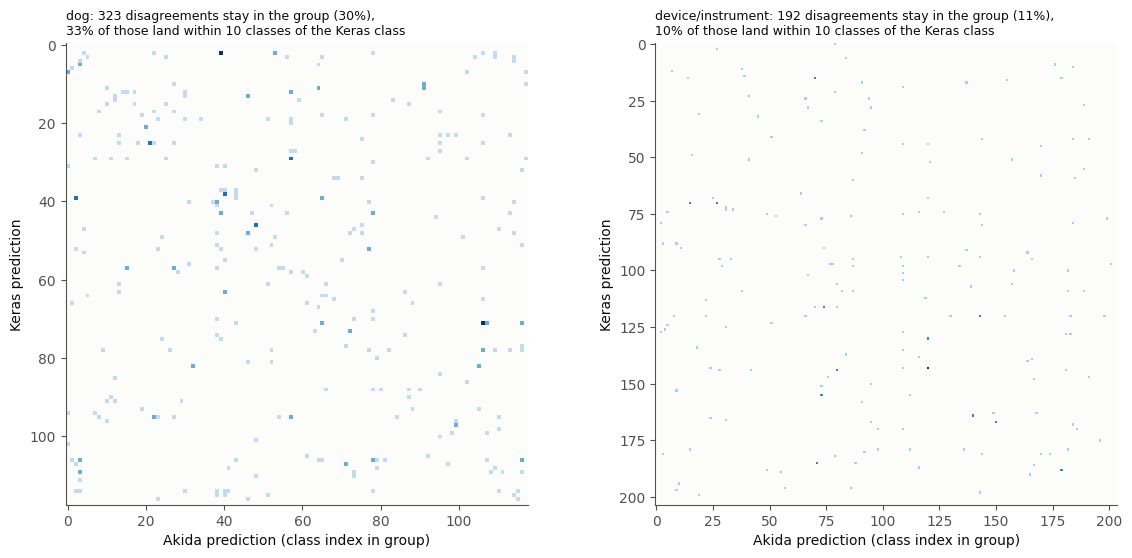

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5.6))
for ax, grp in zip(axes, ['dog', 'device/instrument']):
    labels = sc[sc == grp].index
    pos = {l: i for i, l in enumerate(labels)}
    g = p[(p.sc == grp) & p.dis]
    g = g[g.keras_pred.isin(pos) & g.akida_pred.isin(pos)]
    m = np.zeros((len(labels), len(labels)))
    np.add.at(m, (g.keras_pred.map(pos), g.akida_pred.map(pos)), 1)
    ax.imshow(np.ma.masked_equal(m, 0), cmap='Blues', vmin=0, vmax=max(m.max(), 1), interpolation='nearest')
    ax.set_facecolor('#fcfcfb'); ax.grid(False)
    share = len(g) / max((p.sc == grp).mul(p.dis).sum(), 1)
    near = (abs(g.keras_pred.map(pos) - g.akida_pred.map(pos)) <= 10).mean()
    ax.set_title(f'{grp}: {len(g)} disagreements stay in the group ({share:.0%}),\n'
                 f'{near:.0%} of those land within 10 classes of the Keras class', loc='left', fontsize=9, color=INK)
    ax.set_xlabel('Akida prediction (class index in group)'); ax.set_ylabel('Keras prediction')
fig.tight_layout(); fig.savefig(FIG / 'h1_followup_disagreement_matrices.png', dpi=150)

### Are the top two Keras scores closer when the models disagree?

We reran quantized Keras AkidaNet on the dog and device images using the original JPEG decoding and input size. We took the top score minus the runner-up score, breaking ties by taking the lower ImageNet label index first.

We matched the rerun to the card-run CSV by image ID, corruption and severity, then kept the rows where the Keras top-1 label matched the original. We compared score gaps for agreements and disagreements and repeated the comparison for dog images where both leading Keras labels were breeds.

To regenerate the score CSV, run this command from the notebook's directory. We used Python 3.11 on Linux with `cnn2snn==2.19.3`, `tensorflow==2.19.1`, `pandas==2.2.3`, and the original [BrainChip checkpoint](https://data.brainchip.com/models/AkidaV1/akidanet/akidanet_imagenet_224_alpha_50_iq8_wq4_aq4.h5).

```sh
python export_h1_scores.py . /path/to/akidanet_imagenet_224_alpha_50_iq8_wq4_aq4.h5 results_card/keras_top2_h1.csv
```


In [5]:
key = ['image_id', 'corruption', 'severity']
top_two = pd.read_csv('results_card/keras_top2_h1.csv')
h1_images = p[p.sc.isin(['dog', 'device/instrument'])]
scored = h1_images.merge(top_two, on=key, how='outer', validate='one_to_one', indicator=True)
if not scored['_merge'].eq('both').all():
    raise ValueError('H1 scores must cover exactly the dog and device rows in predictions.csv.')
scored['margin'] = scored.keras_top1_score - scored.keras_top2_score
if not np.isfinite(scored.margin).all() or (scored.margin < 0).any():
    raise ValueError('H1 margins must be finite and nonnegative.')

matches = scored.keras_pred.eq(scored.keras_top1)
print(f'Keras top-1 reproduced for {matches.sum():,}/{len(scored):,} rows.')
scored = scored.loc[matches].copy()
scored['outcome'] = np.where(scored.dis, 'disagree', 'agree')
summary = scored.groupby(['sc', 'outcome']).margin.agg(images='size', median_margin='median')
print(summary.round(3).to_string())

dogs = scored[scored.sc.eq('dog')]
condition_medians = dogs.groupby(['corruption', 'severity', 'outcome']).margin.median().unstack()
print(f'Dog margins are smaller on disagreements in '
      f'{condition_medians.disagree.lt(condition_medians.agree).sum()} of {len(condition_medians)} conditions.')

both_candidates_dog = dogs.keras_top1.map(sc).eq('dog') & dogs.keras_top2.map(sc).eq('dog')
print('\nDog images whose two leading Keras classes are both dog breeds:')
breed_candidates = dogs[both_candidates_dog]
print(breed_candidates.groupby('outcome').margin.agg(images='size', median_margin='median').round(3).to_string())
breed_medians = breed_candidates.groupby(['corruption', 'severity', 'outcome']).margin.median().unstack().dropna()
print(f'Among these dog-breed candidates, margins are smaller on disagreements in '
      f'{breed_medians.disagree.lt(breed_medians.agree).sum()} of {len(breed_medians)} comparable conditions.')

breed_flips = dogs[dogs.dis & dogs.keras_top1.map(sc).eq('dog') & dogs.akida_pred.map(sc).eq('dog')]
runner_up = breed_flips.akida_pred.eq(breed_flips.keras_top2).sum()
print(f'Akida chose the Keras runner-up in {runner_up} of {len(breed_flips)} within-dog disagreements.')


Keras top-1 reproduced for 9,632/9,660 rows.
                            images  median_margin
sc                outcome                        
device/instrument agree       4403          0.729
                  disagree    1694          0.212
dog               agree       2462          0.642
                  disagree    1073          0.216
Dog margins are smaller on disagreements in 15 of 15 conditions.

Dog images whose two leading Keras classes are both dog breeds:
          images  median_margin
outcome                        
agree       1048          0.726
disagree     339          0.212
Among these dog-breed candidates, margins are smaller on disagreements in 13 of 13 comparable conditions.
Akida chose the Keras runner-up in 196 of 322 within-dog disagreements.


## H2 · Does Gaussian noise keep more animal disagreements within the same superclass?

We expected disagreements on animal images to cross superclasses less often under Gaussian noise than under fog or contrast. We selected images by their true label (dog, other mammal, bird, reptile or amphibian, fish, or invertebrate). We then counted a disagreement as crossing superclasses if the two predicted labels belonged to different groups.

For each condition, we bootstrapped the crossing share by resampling only animal images where the models disagreed. We needed the top of the noise interval to sit below the bottom of both the fog and contrast intervals at least twice across severities 1–3.

Noise significantly lower than both in 0 of severities 1-3
Verdict H2: REJECTED


share                             lo                        \
corruption contrast    fog gaussian_noise contrast    fog gaussian_noise   
severity                                                                   
1             0.374  0.402          0.420    0.299  0.329          0.354   
2             0.474  0.449          0.582    0.408  0.380          0.522   
3             0.690  0.557          0.676    0.631  0.496          0.622   
4             0.841  0.619          0.770    0.799  0.557          0.718   
5             0.832  0.603          0.767    0.786  0.539          0.715   

                 hi                       noise_lower  
corruption contrast    fog gaussian_noise              
severity                                               
1             0.448  0.482          0.486       False  
2             0.540  0.517          0.643       False  
3             0.745  0.619          0.729       False  
4             0.879  0.680          0.815       False  
5             0.875  0.664          0.818       False

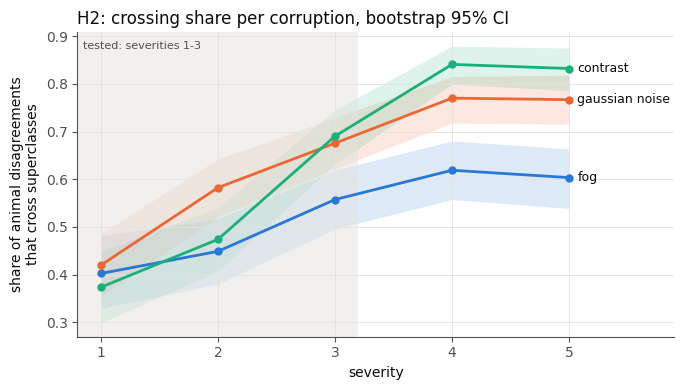

In [6]:
a = p[p.sc.isin(ANIMALS) & p.dis].copy()
a['cross'] = a.keras_pred.map(sc) != a.akida_pred.map(sc)
rows = []
for (c, s), g in a.groupby(['corruption', 'severity']):
    b = boot_rate(g.cross)
    rows.append(dict(corruption=c, severity=s, n=len(g), share=g.cross.mean(),
                     lo=np.quantile(b, .025), hi=np.quantile(b, .975)))
h2 = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(7, 4))
for c, col in zip(CORR, [BLUE, ORANGE, AQUA]):
    t = h2[h2.corruption == c]
    ax.fill_between(t.severity, t.lo, t.hi, color=col, alpha=.15, lw=0)
    ax.plot(t.severity, t.share, color=col, marker='o', ms=5)
    ax.annotate(c.replace('_', ' '), (5, t.share.iloc[-1]), xytext=(6, 0), textcoords='offset points',
                va='center', color=INK, fontsize=9)
ax.axvspan(0.8, 3.2, color=GRID, alpha=.5, lw=0); ax.text(0.85, 0.97, 'tested: severities 1-3',
                                                          transform=ax.get_xaxis_transform(), color=MUTED, fontsize=8, va='top')
ax.set_xticks(range(1, 6)); ax.set_xlim(0.8, 5.9); ax.set_xlabel('severity')
ax.set_ylabel('share of animal disagreements\nthat cross superclasses')
ax.set_title('H2: crossing share per corruption, bootstrap 95% CI', loc='left', color=INK)
fig.tight_layout(); fig.savefig(FIG / 'h2_crossing_share.png', dpi=150)

w = h2.pivot(index='severity', columns='corruption', values=['share', 'lo', 'hi'])
w['noise_lower'] = (w['hi', 'gaussian_noise'] < w['lo', 'fog']) & (w['hi', 'gaussian_noise'] < w['lo', 'contrast'])
n = int(w.loc[1:3, 'noise_lower'].sum())
print(f'Noise significantly lower than both in {n} of severities 1-3')
print('Verdict H2:', 'NOT rejected' if n >= 2 else 'REJECTED')
w.round(3)

### Where do the animal disagreements go?

Each panel pools severities 1–3 for one corruption. Rows show the superclass predicted by Keras and columns show the superclass predicted by Akida. Each cell is a share of its row. On the diagonal, the models picked different labels within the same superclass.

The number on the right gives the row total. Rows with fewer than 10 observations are gray. We printed cell values of 10% or more to keep the plots readable.

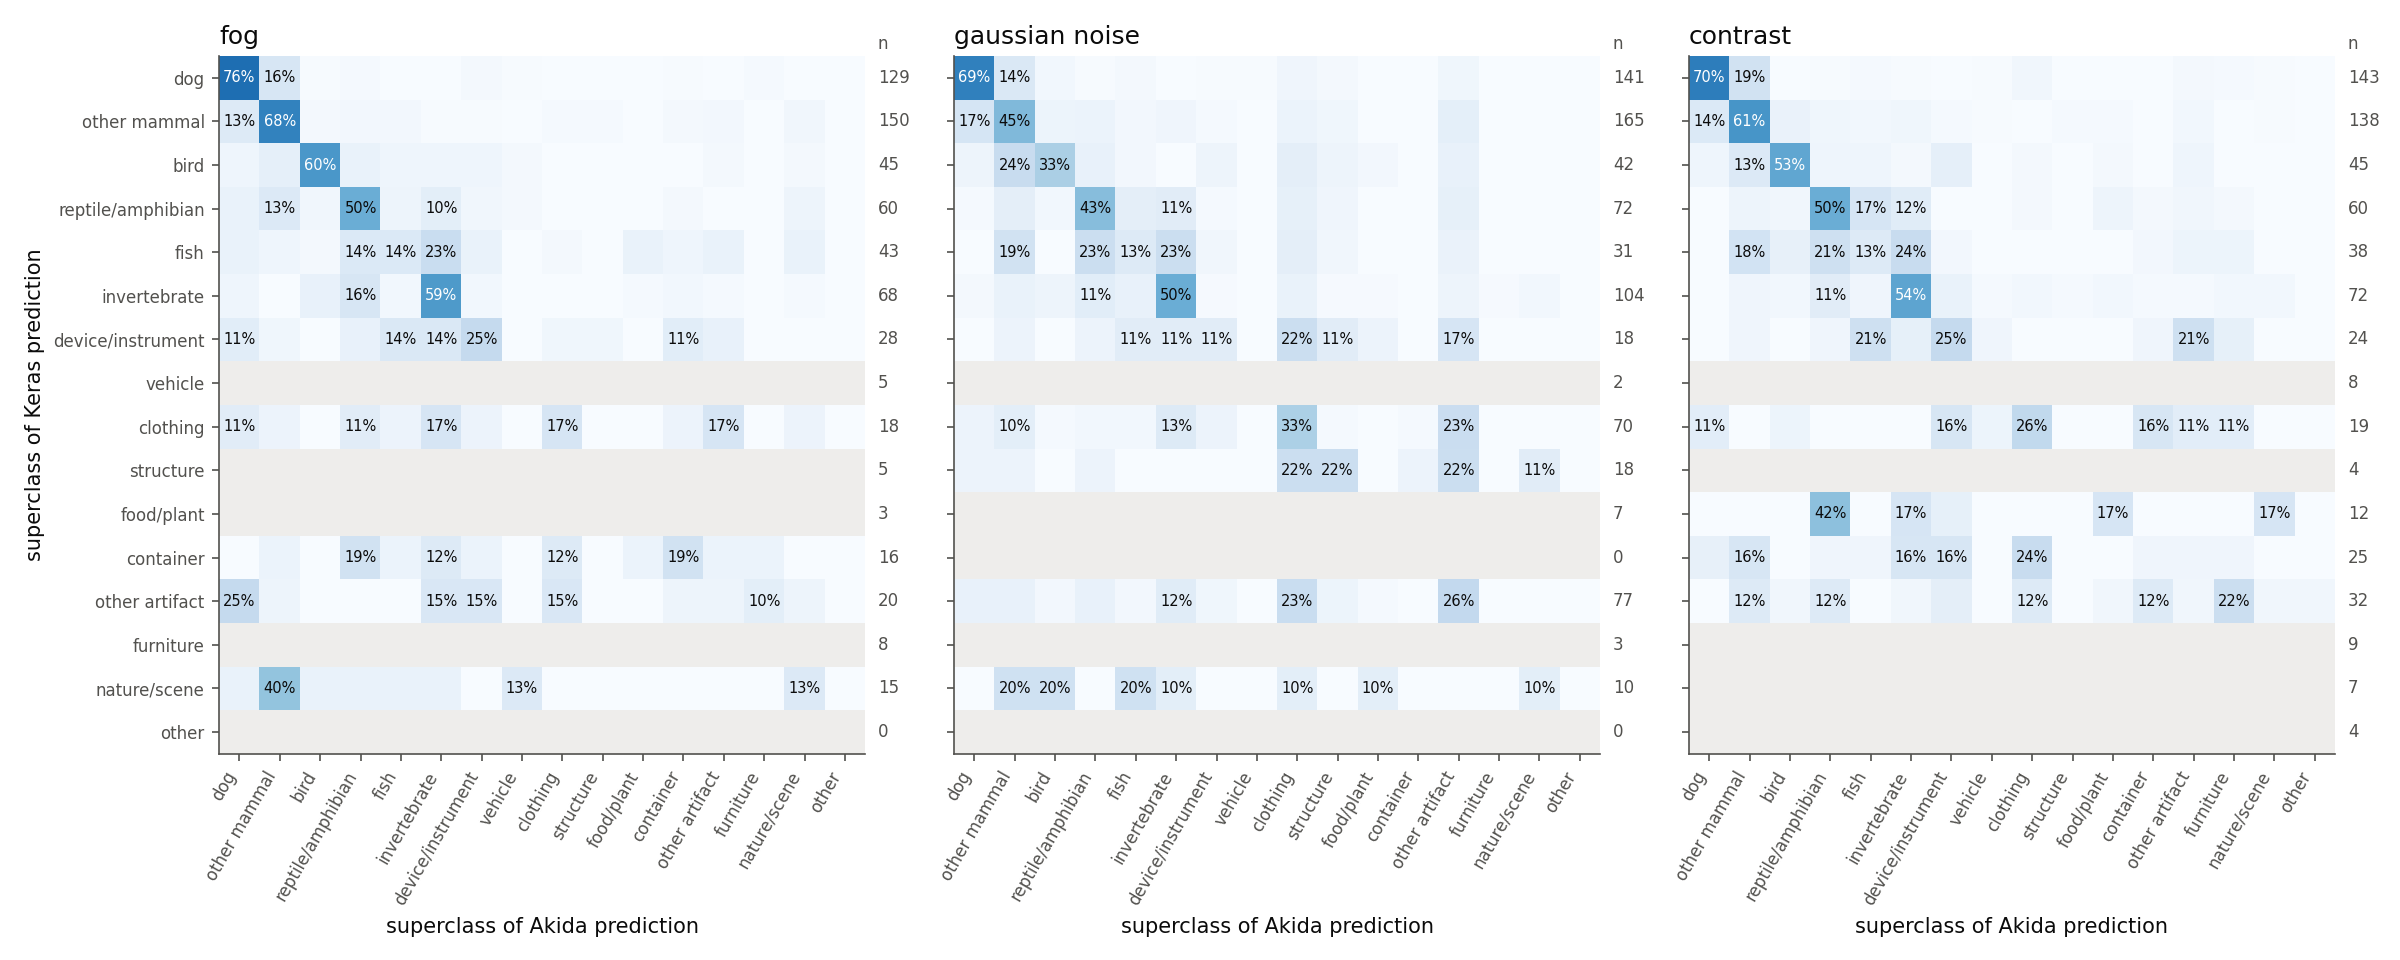

In [7]:
order = ANIMALS + [name for name in sc.value_counts().index if name not in ANIMALS]
fig, axes = plt.subplots(1, 3, figsize=(16, 6.4), sharey=True)
cmap = plt.get_cmap('Blues').with_extremes(bad='#eeedeb')

for ax, c in zip(axes, CORR):
    g = a[(a.corruption == c) & (a.severity <= 3)]
    counts = pd.crosstab(g.keras_pred.map(sc), g.akida_pred.map(sc)).reindex(
        index=order, columns=order, fill_value=0
    )
    row_counts = counts.sum(axis=1)
    shares = counts.div(row_counts, axis=0).where(row_counts >= 10, axis=0)
    ax.imshow(shares, cmap=cmap, vmin=0, vmax=1, aspect='auto', interpolation='nearest')
    ax.grid(False)
    ax.set_xticks(range(len(order)), order, rotation=60, ha='right', fontsize=8)

    ax.text(1.02, 1.01, 'n', transform=ax.transAxes, fontsize=8, color=MUTED)
    for i, count in enumerate(row_counts):
        ax.text(1.02, i, str(count), transform=ax.get_yaxis_transform(), va='center',
                fontsize=8, color=MUTED)
    for i, j in np.argwhere(shares.to_numpy() >= .1):
        share = shares.iat[i, j]
        ax.text(j, i, f'{share:.0%}', ha='center', va='center', fontsize=7,
                color='white' if share > .5 else INK)

    ax.set_title(c.replace('_', ' '), loc='left', color=INK)
    ax.set_xlabel('superclass of Akida prediction')

axes[0].set_yticks(range(len(order)), order, fontsize=8)
axes[0].set_ylabel('superclass of Keras prediction')
fig.tight_layout()
fig.savefig(FIG / 'h2_followup_superclass_confusion.png', dpi=150)

## Card energy per frame

The AKD1000 statistics give one average per condition, calculated from batches of 250 images. The numbers are in millijoules per frame and include floor power.

The x-axis follows `run_card.log`. The card ran fog first, then Gaussian noise, then contrast, in severity order within each block. Each condition took about 195 seconds. The y-axis is zoomed in so the differences are visible.

Spearman r(energy, run order) = -0.82
Spearman r(energy, agreement) = 0.59


model                    akidanet_akida_akd1000  akidanet_keras_quantized
corruption     severity                                                  
contrast       1                         0.3955                    0.3960
               2                         0.2930                    0.2895
               3                         0.1425                    0.1300
               4                         0.0320                    0.0285
               5                         0.0075                    0.0080
fog            1                         0.3770                    0.3820
               2                         0.2825                    0.2770
               3                         0.2040                    0.1985
               4                         0.1715                    0.1710
               5                         0.0720                    0.0745
gaussian_noise 1                         0.2985                    0.2995
               2                         0.1360                    0.1450
               3                         0.0465                    0.0440
               4                         0.0130                    0.0130
               5                         0.0055                    0.0045

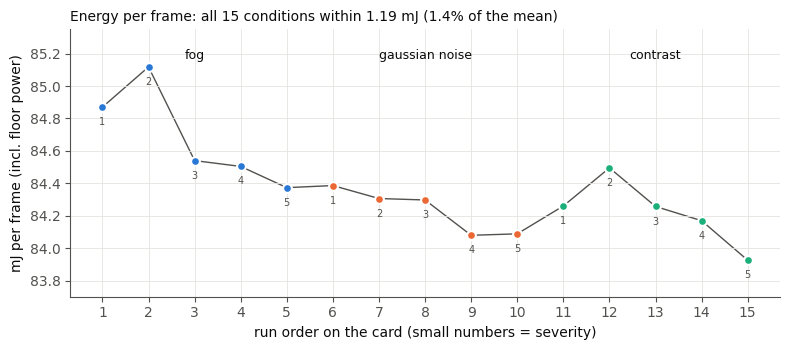

In [8]:
e = pd.read_csv('results_card/energy.csv')  # rows are in run order (checked against run_card.log)
e['run'] = range(1, len(e) + 1)
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(e.run, e.energy_per_inference, color=MUTED, lw=1, zorder=1)
for c, col in zip(CORR, [BLUE, ORANGE, AQUA]):
    t = e[e.corruption == c]
    ax.scatter(t.run, t.energy_per_inference, color=col, s=40, zorder=2, edgecolor='white', lw=1.5)
    ax.text(t.run.mean(), e.energy_per_inference.max() + .05, c.replace('_', ' '), ha='center', color=INK, fontsize=9)
    for _, r in t.iterrows():
        ax.annotate(f'{r.severity}', (r.run, r.energy_per_inference), xytext=(0, -13), textcoords='offset points',
                    ha='center', fontsize=7, color=MUTED)
ax.set_xticks(e.run); ax.set_xlabel('run order on the card (small numbers = severity)')
ax.set_ylabel('mJ per frame (incl. floor power)'); ax.set_ylim(83.7, 85.35)
spread = e.energy_per_inference.max() - e.energy_per_inference.min()
ax.set_title(f'Energy per frame: all 15 conditions within {spread:.2f} mJ '
             f'({spread / e.energy_per_inference.mean():.1%} of the mean)', loc='left', color=INK, fontsize=10)
fig.tight_layout(); fig.savefig(FIG / 'energy_per_condition.png', dpi=150)

agr = pd.read_csv('results_card/agreement.csv').merge(e, on=['corruption', 'severity'])
print('Spearman r(energy, run order) =', round(e.energy_per_inference.corr(e.run, method='spearman'), 2))
print('Spearman r(energy, agreement) =', round(agr.energy_per_inference.corr(agr.agreement, method='spearman'), 2))
acc = pd.read_csv('results_card/accuracy.csv')
acc.pivot_table(index=['corruption', 'severity'], columns='model', values='top1')

## Results

### H1 · Dogs and devices

We rejected H1. The bootstrap interval for the difference in disagreement rates was above zero in 3 of 15 conditions (contrast 4 and Gaussian noise 4–5). We needed 8. At severities 1 and 2, the dog estimates were higher under contrast and lower under fog and noise. All six intervals included zero.

When the models disagreed, both predictions stayed in the true superclass for 30% of dog images and 11% of device images. The Keras rerun reproduced the original top-1 label on 9,632 of 9,660 rows. We left the other 28 out of the score comparison.

For dog images where Keras ranked two breeds highest, the median score gap was 0.212 on disagreements and 0.726 on agreements. The gap was smaller on disagreements in all 13 conditions where we could compare both outcomes in this subset. When both models chose a dog breed but picked different breeds, Akida chose the Keras runner-up in 196 of 322 cases (61%). Devices showed a similar score pattern, with median gaps of 0.212 on disagreements and 0.729 on agreements.

### H2 · Animal disagreements under noise, fog and contrast

We rejected H2. Gaussian noise met the interval rule at none of the three severities. It had the highest share of cross-superclass disagreements at severity 1 (42%) and severity 2 (58%). At severity 3, the share was 68% for noise, 69% for contrast and 56% for fog. Keras was less accurate under noise at all three severities, so equal severity did not mean equal difficulty for the model.

Across severities 1–3, Akida predicted clothing or other artifact for 126 of 436 cross-superclass disagreements under noise (29%), 46 of 341 under contrast (13%) and 26 of 294 under fog (9%). The counts show where the predictions went. Testing whether texture drove those predictions would need a separate analysis.

### Accuracy, agreement and energy

Both models were wrong in 86.5% of disagreements, rising from 70.6% at severity 1 to 96.5% at severity 5. Agreement ranged from 63% to 79% by condition. The two top-1 accuracies were within 1.3 percentage points in every condition.

Energy ranged from 83.925 to 85.118 mJ per frame, a spread of 1.19 mJ including floor power. Readings tended to fall as the run went on (Spearman's r = −0.82). We ran each condition once in a fixed order, so we can't tell how much of the change came from corruption and how much came from drift during the run.

---


## H3: Fog creates background-driven error sub-clusters (UMAP View)
Under high severity fog, the latent embeddings of misclassified images do not just form one random mass; they form distinct, dense sub-clusters grouped by shared background colors (e.g., all sky/outdoor backgrounds) rather than primary objects. 

* We reject H3 if: The UMAP error clusters do not visually correlate with shared background traits.

* To dig deeper: We will isolate the densest error clusters in the 2D projection, inspect the original input images within them, and determine exactly what visual features (like color palettes or backgrounds) distinguish these dense sub-clusters from the sparser regions of the latent space.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import umap
import tensorflow as tf

/home/user/.venvs/ai-vis-2026/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
2026-11-11 09:43:13.179581: I external/local_xla/xla/tsl/cuda/cudart_stub.cc:32] Could not find cuda drivers on your machine, GPU will not be used.
2026-11-11 09:43:13.190242: I external/local_xla/xla/tsl/cuda/cudart_stub.cc:32] Could not find cuda drivers on your machine, GPU will not be used.
2026-11-11 09:43:13.204407: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1794386593.225485   12995 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1794386593.231192   12995 cuda_blas.cc:1407

In [2]:
df = pd.read_parquet("results_card/predictions_with_embeddings.parquet")
os.makedirs("../figures/phase1_human", exist_ok=True)

#df_sample = df.groupby(["corruption", "severity"]).sample(n=200, random_state=42) # subsample, 30k images is too heavy for UMAP memory limits
features = np.vstack(df["embedding"].values)

reducer = umap.UMAP(n_neighbors=15, min_dist=0.1, random_state=42)
embeddings_2d = reducer.fit_transform(features)

df["umap_x"] = embeddings_2d[:, 0]
df["umap_y"] = embeddings_2d[:, 1]

/home/user/.venvs/ai-vis-2026/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


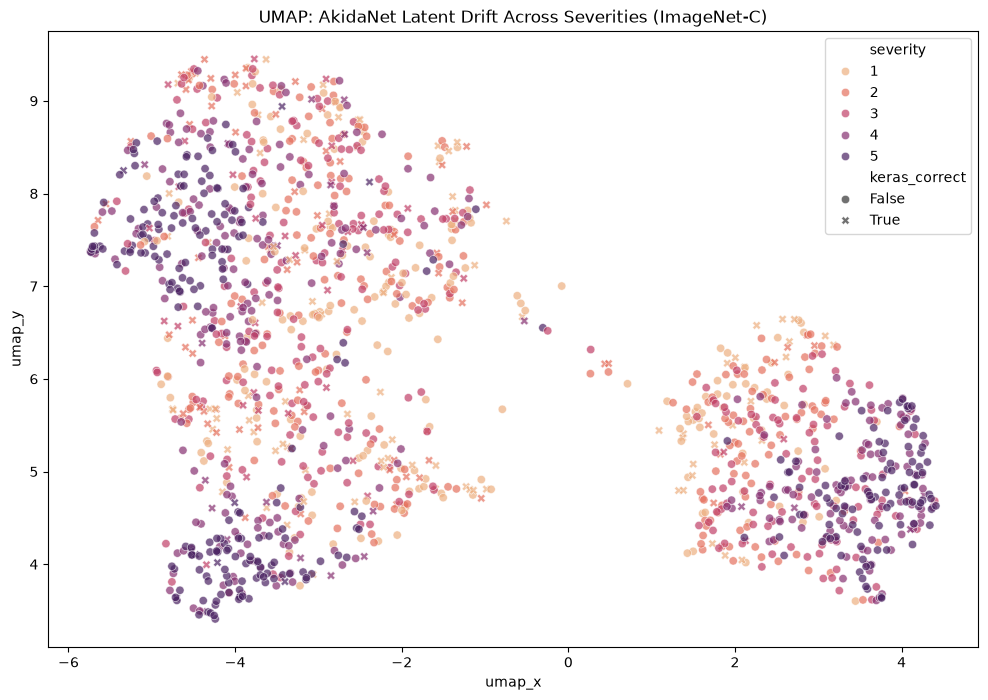

In [3]:
plt.figure(figsize=(12, 8))

sns.scatterplot(data=df, x="umap_x", y="umap_y",hue="severity", style="keras_correct", alpha=0.7, palette="flare")

plt.title("UMAP: AkidaNet Latent Drift Across Severities (ImageNet-C)")

plt.savefig("../figures/phase1_human/akidanet_umap_drift.png", bbox_inches="tight")#store image
plt.show()

Found 47 misclassified images in the selected UMAP cluster.


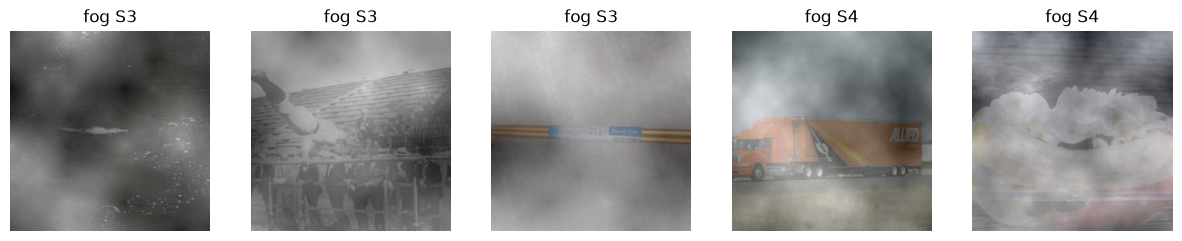

In [4]:
X_MIN, X_MAX = -5.0, -4.0   
Y_MIN, Y_MAX = 3.5, 4.5 

# filter df to grab only the misclassified images sitting inside that coordinate box
cluster_imgs = df[(df["umap_x"] >= X_MIN) & (df["umap_x"] <= X_MAX) & (df["umap_y"] >= Y_MIN) & (df["umap_y"] <= Y_MAX) &(df["keras_correct"] == False)]

print(f"Found {len(cluster_imgs)} misclassified images in the selected UMAP cluster.")

fig, axes = plt.subplots(1, min(5, len(cluster_imgs)), figsize=(15, 3))
if len(cluster_imgs) > 0:
    if len(cluster_imgs) == 1: axes = [axes]
        
    for ax, (_, row) in zip(axes, cluster_imgs.head(5).iterrows()):
        img_path = f"../data/imagenet_subset/imagenet-c/{row['corruption']}/{row['severity']}/{row['image_id']}"
        img = tf.keras.utils.load_img(img_path, target_size=(224, 224))
        ax.imshow(img)
        ax.axis('off')
        ax.set_title(f"{row['corruption']} S{row['severity']}")
plt.show()

## H4: Low contrast forces a systemic collapse into "textureless" fallback classes (Confusion Matrix View)
The top classes most degraded by low contrast will systematically shift their predictions into a few specific "fallback" classes that naturally lack fine internal edges or details.

* We reject H4 if: The difference matrix shows the false predictions spreading uniformly across many classes rather than concentrating in 1 or 2 distinct columns.

* To dig deeper: We will identify the specific fallback classes dominating the columns of the difference matrix and inspect the images to understand the shared visual properties (e.g., smooth shapes, gray tones) that cause the model's behavior to default to them.

In [5]:
from sklearn.metrics import confusion_matrix

In [6]:
df = pd.read_csv("results_card/predictions.csv")
os.makedirs("../figures/phase1_human", exist_ok=True)

df_mismatch = df[df["keras_pred"] != df["akida_pred"]] # SNN hardware disagrees with Keras sim

# get the worst 15 classes (to not show 1000 classes)
top_15_unstable = df_mismatch["keras_pred"].value_counts().head(15).index.tolist() 
df_filtered = df[df["keras_pred"].isin(top_15_unstable)].copy()

# "Other" bucket
OTHER_ID = 9999
df_filtered.loc[~df_filtered["akida_pred"].isin(top_15_unstable), "akida_pred"] = OTHER_ID
cm_labels = top_15_unstable + [OTHER_ID]
tick_labels = [str(c) for c in top_15_unstable] + ["Other"]


In [7]:
# confusion Matrix
cm = confusion_matrix(df_filtered["keras_pred"], df_filtered["akida_pred"], labels=cm_labels, normalize="true")

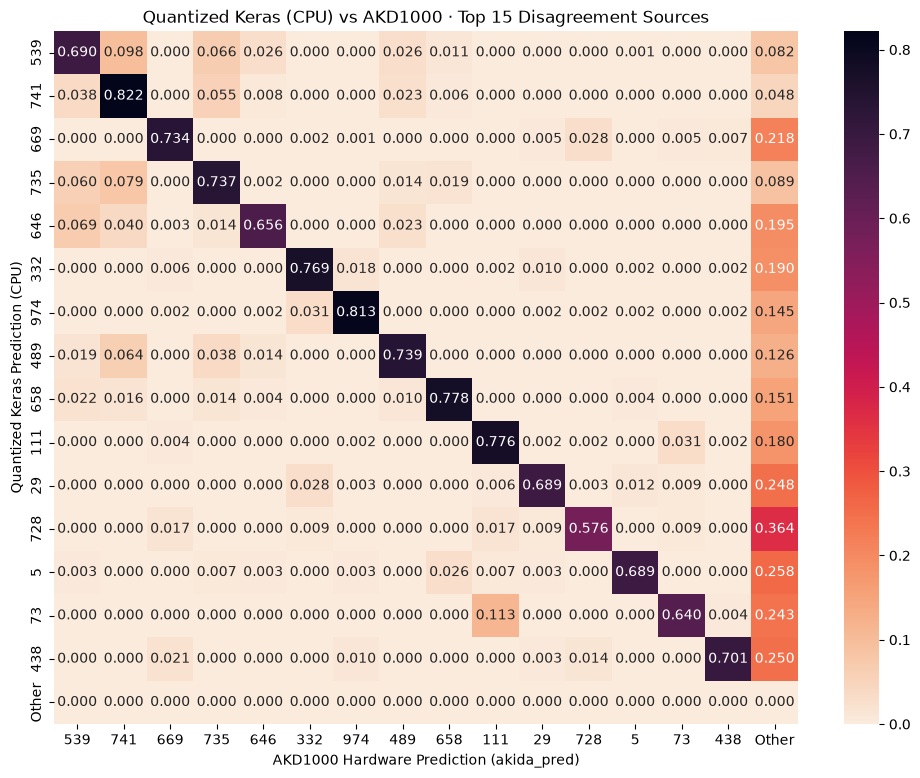

In [8]:
plt.figure(figsize=(12, 9))
sns.heatmap(cm, annot=True, fmt=".3f", cmap="rocket_r", 
            xticklabels=tick_labels, yticklabels=tick_labels)
plt.title("Quantized Keras (CPU) vs AKD1000 · Top 15 Disagreement Sources")
plt.xlabel("AKD1000 Hardware Prediction (akida_pred)")
plt.ylabel("Quantized Keras Prediction (CPU)")
plt.savefig("../figures/phase1_human/keras_vs_akida_hardware_shift.png", bbox_inches="tight")
plt.show()

Max deviation found: 27 images where Keras predicted 73 but Akida hardware predicted 111


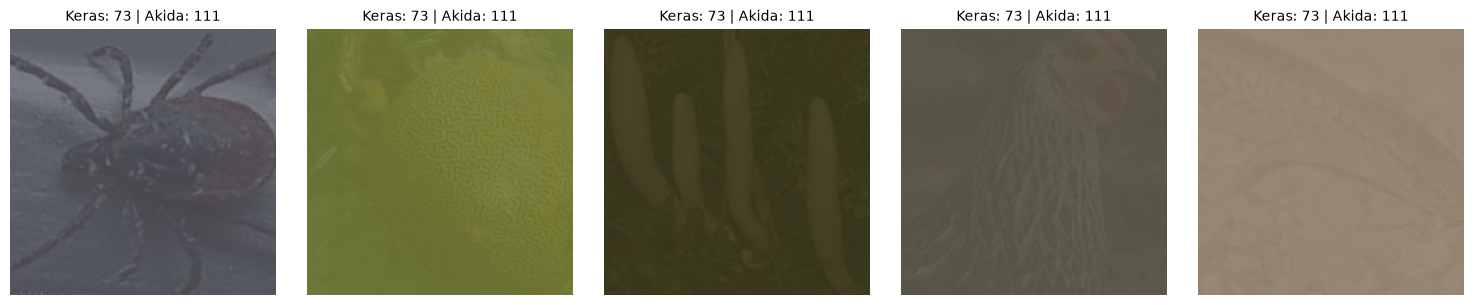

In [9]:
# find the pair with the biggest error shift
cm_off_diag = cm.copy()
np.fill_diagonal(cm_off_diag, 0)

# remove "9999" (other) column to find only classes that are actually inside our subset
other_idx = cm_labels.index(9999)
cm_off_diag[:, other_idx] = 0

max_idx = np.unravel_index(np.argmax(cm_off_diag, axis=None), cm_off_diag.shape)
KERAS_BASELINE_ID = cm_labels[max_idx[0]]
AKIDA_DEVIATION_ID = cm_labels[max_idx[1]]

drill_down = df_filtered[(df_filtered["keras_pred"] == KERAS_BASELINE_ID) & (df_filtered["akida_pred"] == AKIDA_DEVIATION_ID)]

print(f"Max deviation found: {len(drill_down)} images where Keras predicted {KERAS_BASELINE_ID} but Akida hardware predicted {AKIDA_DEVIATION_ID}")

# plot the first 5 images
fig, axes = plt.subplots(1, min(5, len(drill_down)), figsize=(15, 3))
if len(drill_down) > 0:
    if len(drill_down) == 1: axes = [axes]
        
    for ax, (_, row) in zip(axes, drill_down.head(5).iterrows()):
        img_path = f"../data/imagenet_subset/imagenet-c/{row['corruption']}/{row['severity']}/{row['image_id']}"
        
        try:
            img = tf.keras.utils.load_img(img_path, target_size=(224, 224))
            ax.imshow(img)
        except Exception as e:
            ax.text(0.5, 0.5, 'Image Missing', ha='center', va='center')
            
        ax.axis('off')
        ax.set_title(f"Keras: {row['keras_pred']} | Akida: {row['akida_pred']}", fontsize=10)

plt.tight_layout()
plt.show()

## Results

### Conclusion for Hypothesis 3

Based on the UMAP projection and the drill-down visual inspection, we fail to reject Hypothesis 3. <br>

**Visual Evidence & Behavioral Shift:** <br>
The UMAP plot demonstrates that as corruption severity increases, the latent embeddings do not scatter randomly; instead, they collapse into distinct, highly dense sub-clusters. <br>

When we drill down into a specific high-density error cluster, the sampled images reveal a clear, systematic failure mode. As seen in the output, despite containing entirely different ground-truth objects (e.g., a truck, stadium seating, ...), all the misclassified images are heavily dominated by the exact same cloudy, gray-white fog artifact. The synthetic fog overlay washes out the fine details of the primary objects and unifies the images visually.  <br>

This confirms that under heavy corruption, AkidaNet's penultimate layer is no longer extracting features from the underlying objects. Instead, the network's latent representations are hijacked by the dominant, shared "texture" of the fog itself, forcing completely unrelated classes into the exact same region of the latent space.


### Conclusion for Hypothesis 4

Based on the drill-down images showing the maximum deviation between the Keras simulation (Class 73) and the physical Akida hardware (Class 111), we fail to reject Hypothesis 4. The model does indeed systematically collapse into specific fallback classes under low contrast.

**Visual Evidence & Hardware Implications:** <br>
The displayed images share extremely dark, low-contrast conditions where fine, intricate textures (such as insect legs, feathers, and organic ridges) are heavily obscured. Under low contrast, pixel intensity gradients become very weak. 

While the Keras simulator retains enough mathematical precision to classify these features as class 73, the actual Akida hardware relies on 4-bit quantization and event-based spike thresholds. It is highly likely that these weak, low-contrast edges fail to trigger enough spikes on the physical chip (a phenomenon known as "spike death"). Without these crucial high-frequency feature activations, the SNN hardware systematically defaults to the fallback class 111.